# MyDeZero CPU Optimization

## From the Iris benchmark to four changes

The Iris LeNet benchmark showed that MyDeZero took longer than PyTorch to
train and run inference on CPU. The original weight initialization and the
many temporary arrays in DeZero-style convolution and pooling were starting
points for four experiments.

| Round | Question | Change |
| --- | --- | --- |
| 1. Weight dtype | Why do FP32 layers create FP64 weights in some NumPy versions? | Cast after applying the initialization scale in `Linear`, `Conv2d`, and `Deconv2d`. |
| 2. Max pooling | Why build windows and argmax indices when no backward pass is recorded? | Compare `2 × 2` stride-2 windows directly under `no_grad()`. |
| 3. Spatial convolution | Can the input windows be packed once for matrix multiplication? | Pack strided windows directly into rows for forward and weight gradients. |
| 4. Pointwise convolution | Does a `1 × 1` convolution need to expand spatial windows? | Use matrix multiplication directly for unpadded stride-1 forward and weight gradients. |

The CPU baseline uses MyDeZero's original DeZero-style operator paths. One
comparison uses the dtype produced by the old initializer on the current
NumPy version. A second comparison fixes FP32 and runs all eight combinations
of the three operator changes, with PyTorch eager as an external reference.

```text
python -m pip install -e .
python -m pip install scikit-learn torch threadpoolctl ipykernel
```

Run cells in order in a CPU kernel. The MNIST subset uses the standard
MyDeZero dataset cache. Runtime depends on the CPU and NumPy's BLAS library.

In [1]:
from dataclasses import dataclass
from contextlib import contextmanager, nullcontext
from itertools import product
import platform
from statistics import median
from time import perf_counter
import tracemalloc
from unittest.mock import patch

import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_iris
from sklearn.metrics import precision_recall_fscore_support
from threadpoolctl import threadpool_info, threadpool_limits
import torch
from torch import nn

from mydezero import Model, Variable, no_grad, test_mode
from mydezero.datasets import MNIST
import mydezero.functions as F
import mydezero.functions_conv as FC
import mydezero.layers as L
from mydezero.models import MLP
from mydezero.optimizers import Adam

BATCHES = (1, 16, 64)
THREADS = (1, 4)
SEEDS = (42, 43, 44)
ROUNDS, CALLS = 5, 7
OPERATORS = ('Pool', 'Pack', '1x1')
VARIANTS = sorted(
    (frozenset(o for o, enabled in zip(OPERATORS, bits) if enabled)
     for bits in product((False, True), repeat=3)),
    key=lambda v: (len(v), tuple(o for o in OPERATORS if o in v)),
)
BASE, ALL = VARIANTS[0], VARIANTS[-1]


def label(variant):
    return '+'.join(o for o in OPERATORS if o in variant) or 'Baseline'


blas = ', '.join(f"{p['internal_api']} {p['version']}" for p in threadpool_info()
                 if p['user_api'] == 'blas')
print(f'{platform.system()} / {platform.processor()} / Python {platform.python_version()}')
print(f'NumPy {np.__version__} ({blas}) / PyTorch {torch.__version__}')

Windows / Intel64 Family 6 Model 198 Stepping 2, GenuineIntel / Python 3.9.25
NumPy 2.0.2 (openblas 0.3.27, openblas 0.3.27) / PyTorch 2.8.0+cu128


## Round 1 · Weight initialization

Check the dtype of the original cast-then-scale expression in the current
NumPy runtime. Then check initialized weights, output, and gradients on
the three layer types. The end-to-end test later assigns the same initial
values either the dtype observed here or FP32. This isolates work performed
in wider precision from the one-time initialization operation. On a NumPy
version where the old expression already produces FP32, both controls use
the same precision and any measured difference reflects timing variability.

In [2]:
legacy_dtype = (np.ones(3, dtype=np.float32) * np.sqrt(1 / 3)).dtype
print(f'Old cast-then-scale result on NumPy {np.__version__}: {legacy_dtype}')
for layer, shape in ((L.Linear(4), (2, 3)), (L.Conv2d(4, 3), (2, 3, 5, 5)),
                     (L.Deconv2d(4, 3), (2, 3, 5, 5))):
    x = Variable(np.ones(shape, dtype=np.float32))
    out = layer(x)
    out.sum().backward()
    assert x.grad.dtype == out.dtype == np.float32
    assert all(p.dtype == p.grad.dtype == np.float32 for p in layer.params())
    print(f'{type(layer).__name__}: weights, output, and gradients are FP32')

Old cast-then-scale result on NumPy 2.0.2: float64
Linear: weights, output, and gradients are FP32
Conv2d: weights, output, and gradients are FP32
Deconv2d: weights, output, and gradients are FP32


## Rounds 2–4 · Pooling and convolution

Measure convolution forward and weight gradients independently, using FP32 activations and fixed upstream gradients. Test a LeNet-style convolution, a deeper MNIST convolution, a VGG-style convolution and two pointwise ResNet-style stems with equivalent values in contiguous and channels-last storage. Also measure inference max pooling on a channels-last activation. The timings prewarm each path and rotate execution order over five rounds of seven calls. P50 is the median of round medians, and P95 is taken over individual calls. Peak tracked allocations cover the call where Python/NumPy accounts for the allocation. BLAS workspaces and process memory may be outside that measurement.

In [3]:
@dataclass(frozen=True)
class Workload:
    name: str
    train: tuple
    test: tuple
    channels: tuple
    kernels: tuple
    hidden: tuple
    classes: int
    epochs: int
    training_batch: int

    @property
    def flattened(self):
        size = self.train[0].shape[-1]
        for kernel in self.kernels:
            size = (size - kernel + 1) // 2
        return self.channels[-1] * size * size


def toy_data(per_class, rng):
    patterns = np.zeros((3, 1, 8, 8), dtype=np.float32)
    patterns[0, 0, :, 1:3] = 1
    patterns[1, 0, 1:3, :] = 1
    patterns[2, 0, 4:7, 4:7] = 1
    y = rng.permutation(np.repeat(np.arange(3), per_class))
    x = patterns[y] + np.float32(0.25) * rng.standard_normal((len(y), 1, 8, 8), dtype=np.float32)
    return x, y


def iris_data():
    iris = load_iris()
    rng = np.random.default_rng(42)
    classes = [rng.permutation(np.flatnonzero(iris.target == k)) for k in range(3)]
    train = rng.permutation(np.concatenate([ids[:40] for ids in classes]))
    test = rng.permutation(np.concatenate([ids[40:] for ids in classes]))
    values = iris.data.astype(np.float32)
    x = (values - values[train].mean(axis=0)) / values[train].std(axis=0)
    x = x.reshape(-1, 1, 2, 2).repeat(16, axis=2).repeat(16, axis=3)
    return (x[train], iris.target[train]), (x[test], iris.target[test])


def mnist_split(train, per_class):
    ds = MNIST(train=train)
    rng = np.random.default_rng(42 if train else 43)
    classes = [rng.choice(np.flatnonzero(ds.label == k), per_class, replace=False)
               for k in range(10)]
    ids = rng.permutation(np.concatenate(classes))
    return ds.data[ids].astype(np.float32) / np.float32(255), ds.label[ids].astype(np.int64)


rng = np.random.default_rng(42)
iris_train, iris_test = iris_data()
workloads = (
    Workload("Toy CNN", toy_data(128, rng), toy_data(64, rng), (4, 8), (3, 2), (16,), 3, 3, 32),
    Workload("Iris LeNet-style", iris_train, iris_test, (6, 16), (5, 5), (120, 84), 3, 8, 15),
    Workload("MNIST CNN", mnist_split(True, 120), mnist_split(False, 50),
             (16, 32), (3, 3), (128, 64), 10, 3, 64),
)

In [4]:
class ReferencePooling(FC.Pooling):
    def forward(self, x):
        col = FC.im2col_array(x, self.kernel_size, self.stride, self.pad, to_matrix=False)
        n, c, kh, kw, oh, ow = col.shape
        col = col.reshape(n, c, kh * kw, oh, ow)
        self.indexes = col.argmax(axis=2)
        return col.max(axis=2)


class CNN(Model):
    def __init__(self, data):
        super().__init__()
        c1, c2 = data.channels
        k1, k2 = data.kernels
        self.conv1 = L.Conv2d(c1, k1, in_channels=1)
        self.projection = L.Conv2d(c1, 1, in_channels=c1)
        self.conv2 = L.Conv2d(c2, k2, in_channels=c1)
        self.head = MLP(data.hidden + (data.classes,), activation=F.relu)
        self.layers = (self.conv1, self.projection, self.conv2, *self.head.layers)

    def forward(self, x):
        x = F.pooling(F.relu(self.conv1(x)), 2, stride=2)
        x = F.relu(self.projection(x))
        x = F.pooling(F.relu(self.conv2(x)), 2, stride=2)
        return self.head(x.reshape(x.shape[0], -1))


class TorchCNN(nn.Module):
    def __init__(self, data, my_model):
        super().__init__()
        c1, c2 = data.channels
        k1, k2 = data.kernels
        self.conv1 = nn.Conv2d(1, c1, k1)
        self.projection = nn.Conv2d(c1, c1, 1)
        self.conv2 = nn.Conv2d(c1, c2, k2)
        sizes = (data.flattened, *data.hidden, data.classes)
        self.head = nn.ModuleList(nn.Linear(i, j) for i, j in zip(sizes, sizes[1:]))
        with torch.no_grad():
            for module, source in zip((self.conv1, self.projection, self.conv2, *self.head), my_model.layers):
                w = source.W.data
                module.weight.copy_(torch.from_numpy(w.T if w.ndim == 2 else w))
                module.bias.copy_(torch.from_numpy(source.b.data))
        self.eval()

    def forward(self, x):
        x = nn.functional.max_pool2d(self.conv1(x).relu(), 2)
        x = self.projection(x).relu()
        x = nn.functional.max_pool2d(self.conv2(x).relu(), 2).flatten(1)
        for layer in self.head[:-1]:
            x = layer(x).relu()
        return self.head[-1](x)


def make_model(data, seed, weight_dtype=np.float32):
    model = CNN(data)
    with no_grad():
        model(data.train[0][:1])
    rng = np.random.default_rng(seed)
    for layer in model.layers:
        shape = layer.W.shape
        fan_in = shape[0] if len(shape) == 2 else np.prod(shape[1:])
        weights = rng.standard_normal(shape, dtype=np.float32) * np.float32(np.sqrt(2 / fan_in))
        layer.W.data = weights.astype(weight_dtype, copy=False)
        layer.b.data = np.zeros_like(layer.b.data, dtype=np.float32)
    return model


def step(model, optimizer, batch):
    model.cleargrads()
    loss = F.softmax_cross_entropy(model(batch[0]), batch[1])
    loss.backward()
    optimizer.update()
    return loss.data

cpu_conv_mode = FC._cpu_conv_mode
pool_forward = FC.Pooling.forward


@contextmanager
def enabled(variant):
    def dispatch(*args):
        mode = cpu_conv_mode(*args)
        if (mode == 'packed' and 'Pack' in variant
                or mode == 'pointwise' and '1x1' in variant):
            return mode
        return None

    pooling = pool_forward if 'Pool' in variant else ReferencePooling.forward
    with patch.object(FC, '_cpu_conv_mode', dispatch), patch.object(FC.Pooling, 'forward', pooling):
        yield


def torch_step(model, optimizer, batch):
    optimizer.zero_grad(set_to_none=True)
    loss = nn.functional.cross_entropy(model(batch[0]), batch[1])
    loss.backward()
    optimizer.step()
    return loss.detach().item()

In [5]:
def sample_calls(calls):
    for context, call in calls:
        with context():
            for _ in range(5):
                call()
    history = [[] for _ in calls]
    for r in range(ROUNDS):
        row = [[] for _ in calls]
        for j in range(CALLS):
            for k in range(len(calls)):
                i = (r + j + k) % len(calls)
                context, call = calls[i]
                with context():
                    start = perf_counter()
                    call()
                    row[i].append((perf_counter() - start) * 1e3)
        for group, values in zip(history, row):
            group.append(values)
    return [(median(median(values) for values in history_i),
             float(np.percentile(np.concatenate(history_i), 95))) for history_i in history]


def tracked_peak(call):
    call()
    tracemalloc.start()
    try:
        call()
        return tracemalloc.get_traced_memory()[1] / 1024
    finally:
        tracemalloc.stop()

1 thread(s) | LeNet-style 5×5 Forward | P50/P95 ms 4.325/4.992 → 2.454/2.798
1 thread(s) | LeNet-style 5×5 Weight gradient | P50/P95 ms 5.538/5.971 → 3.524/3.829
1 thread(s) | MNIST CNN 3×3 Forward | P50/P95 ms 5.659/6.127 → 4.138/4.695
1 thread(s) | MNIST CNN 3×3 Weight gradient | P50/P95 ms 6.187/6.799 → 4.852/5.083
1 thread(s) | VGG-style 3×3 Forward | P50/P95 ms 39.418/41.176 → 38.261/39.418
1 thread(s) | VGG-style 3×3 Weight gradient | P50/P95 ms 39.010/45.247 → 38.593/42.567
1 thread(s) | ResNet-style NCHW Forward | P50/P95 ms 14.352/16.478 → 4.366/5.050
1 thread(s) | ResNet-style NCHW Weight gradient | P50/P95 ms 15.013/20.115 → 8.088/9.931
1 thread(s) | ResNet-style NHWC storage Forward | P50/P95 ms 15.302/16.702 → 3.948/4.330
1 thread(s) | ResNet-style NHWC storage Weight gradient | P50/P95 ms 16.050/16.732 → 4.847/5.203
1 thread(s) | MNIST CNN 2×2 Forward | P50/P95 ms 10.970/11.324 → 0.861/1.158
4 thread(s) | LeNet-style 5×5 Forward | P50/P95 ms 4.567/5.037 → 2.273/2.688
4 th

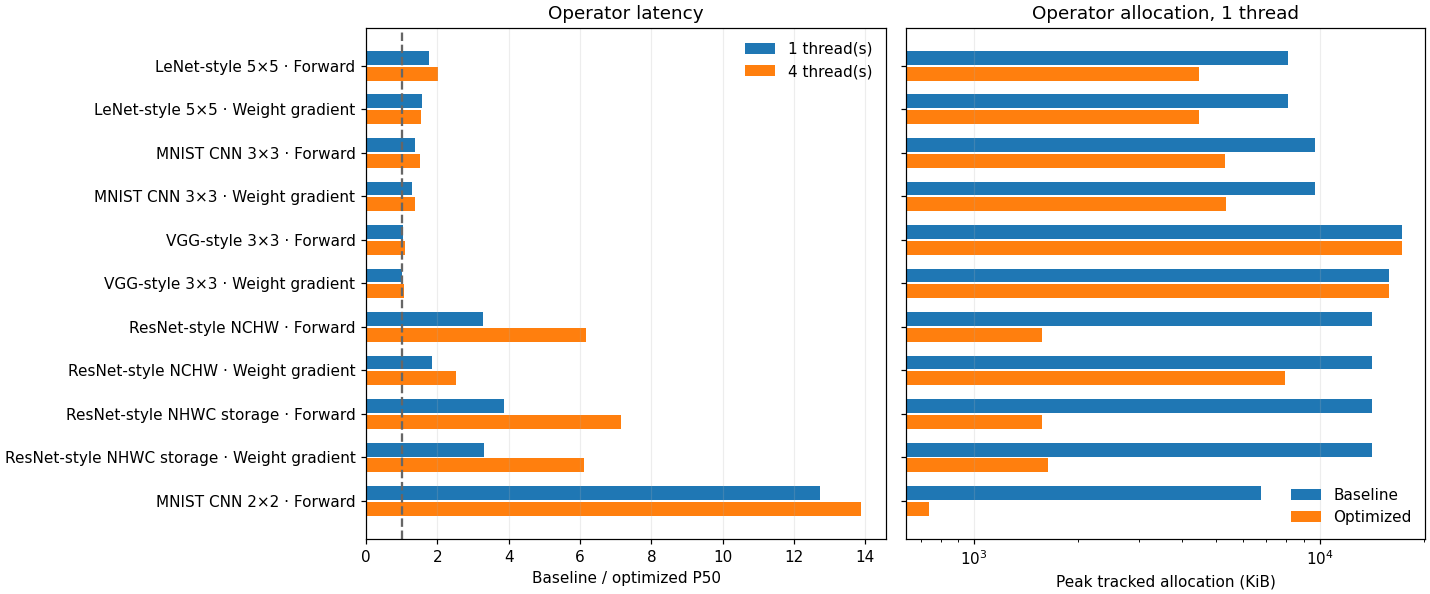

In [6]:
def channels_last(x):
    return np.ascontiguousarray(x.transpose(0, 2, 3, 1)).transpose(0, 3, 1, 2)


def conv_calls(convolution, x, w, gy):
    grad = FC.Conv2DGradW(convolution)
    return {'Forward': lambda: convolution.forward(x, w, None),
            'Weight gradient': lambda: grad.forward(x, gy)}


fixtures = (
    ('Pack', 'LeNet-style 5×5', (64, 1, 28, 28), (6, 1, 5, 5), 0, False),
    ('Pack', 'MNIST CNN 3×3', (64, 16, 13, 13), (32, 16, 3, 3), 0, True),
    ('Pack', 'VGG-style 3×3', (1, 128, 56, 56), (256, 128, 3, 3), 1, True),
    ('1x1', 'ResNet-style NCHW', (8, 256, 28, 28), (64, 256, 1, 1), 0, False),
    ('1x1', 'ResNet-style NHWC storage', (8, 256, 28, 28), (64, 256, 1, 1), 0, True),
)
operator_calls = {}
for i, (feature, name, shape, weight_shape, pad, interleaved) in enumerate(fixtures):
    # Use the same values for both pointwise layouts.
    operator_rng = np.random.default_rng(120 if feature == '1x1' else 100 + i)
    x = operator_rng.standard_normal(shape, dtype=np.float32)
    w = operator_rng.standard_normal(weight_shape, dtype=np.float32)
    x = channels_last(x) if interleaved else x
    with enabled(BASE):
        out = FC.conv2d(x, w, pad=pad)
    gy = operator_rng.standard_normal(out.shape, dtype=np.float32)
    for phase, call in conv_calls(out.creator, x, w, gy).items():
        operator_calls[feature, name, phase] = call

activation = channels_last(np.random.default_rng(130).standard_normal((64, 16, 26, 26), dtype=np.float32))
operator_calls['Pool', 'MNIST CNN 2×2', 'Forward'] = lambda: FC.pooling(activation, 2, stride=2).data

operator_timing, operator_memory = {}, {}
for threads in THREADS:
    with threadpool_limits(limits=threads, user_api='blas'), no_grad():
        for (feature, name, phase), call in operator_calls.items():
            variant = frozenset((feature,))
            with enabled(BASE):
                original = call()
                if threads == 1:
                    baseline_peak = tracked_peak(call)
            with enabled(variant):
                actual = call()
                if threads == 1:
                    operator_memory[feature, name, phase] = (baseline_peak, tracked_peak(call))
            np.testing.assert_allclose(actual, original, rtol=5e-4, atol=2e-3)
            calls = [(lambda: enabled(BASE), call), (lambda: enabled(variant), call)]
            operator_timing[threads, feature, name, phase] = sample_calls(calls)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), layout='constrained', sharey=True)
keys = list(operator_calls)
y = np.arange(len(keys))
for offset, threads in zip((-0.18, 0.18), THREADS):
    ratios = []
    for key in keys:
        ref, opt = operator_timing[(threads, *key)]
        ratios.append(ref[0] / opt[0])
        print(f'{threads} thread(s) | {key[1]} {key[2]} | P50/P95 ms '
              f'{ref[0]:.3f}/{ref[1]:.3f} → {opt[0]:.3f}/{opt[1]:.3f}')
    axes[0].barh(y + offset, ratios, height=0.32, label=f'{threads} thread(s)')
axes[0].axvline(1, color='0.4', linestyle='--')
axes[0].set(xlabel='Baseline / optimized P50', title='Operator latency')
axes[0].set_yticks(y, [f'{name} · {phase}' for _, name, phase in keys])
axes[0].invert_yaxis()
for index, (offset, name) in enumerate(zip((-0.18, 0.18), ('Baseline', 'Optimized'))):
    values = [operator_memory[key][index] for key in keys]
    axes[1].barh(y + offset, values, height=0.32, label=name)
axes[1].set(xlabel='Peak tracked allocation (KiB)', xscale='log', title='Operator allocation, 1 thread')
for ax in axes:
    ax.grid(axis='x', alpha=0.22)
    ax.legend(frameon=False)
plt.show()

## End-to-end benchmark

Every model has two spatial convolutions, two max-pooling layers and a `1 × 1` projection. The Toy CNN uses synthetic images, the Iris LeNet-style model encodes four standardized features into a spatial input, and the MNIST CNN uses 1,200 training and 500 held-out images. The projection lets every workload exercise the pointwise path. Evaluate all eight FP32 combinations, including each operator optimization alone and each leave-one-out combination. A ninth MyDeZero timing uses the old operator paths and the dtype observed in the old initializer.

For quality, fit three pairs of independent FP32 MyDeZero runs with identical seeds, initial FP32 parameters, batches and Adam settings. Report held-out accuracy, macro precision, recall and F1, and show the mean training loss trajectories. Check shared-weight logits and prediction labels for every MyDeZero variant and for PyTorch. PyTorch receives the trained MyDeZero weights for this numerical check.

Inference timings use the same checkpoint and already prepared input tensors. Training timings use fresh copies of the matched weights and measure forward, cross-entropy, backward and Adam updates. Pool acceleration is disabled by gradient recording during training. Training timed calls cover an in-memory repeated batch and exclude preprocessing. NumPy BLAS and PyTorch intra-op threads are controlled separately.

Toy CNN: accuracy, macro precision, macro recall, macro F1
  Baseline          0.7951 / 0.8278 / 0.7951 / 0.7678
  Pool+Pack+1x1     0.7951 / 0.8278 / 0.7951 / 0.7678
  576 shared-weight predictions agreed, maximum MyDeZero logit difference 0.
Iris LeNet-style: accuracy, macro precision, macro recall, macro F1
  Baseline          0.9111 / 0.9127 / 0.9111 / 0.9109
  Pool+Pack+1x1     0.9111 / 0.9127 / 0.9111 / 0.9109
  90 shared-weight predictions agreed, maximum MyDeZero logit difference 0.
MNIST CNN: accuracy, macro precision, macro recall, macro F1
  Baseline          0.9233 / 0.9266 / 0.9233 / 0.9234
  Pool+Pack+1x1     0.9247 / 0.9277 / 0.9247 / 0.9247
  1500 shared-weight predictions agreed, maximum MyDeZero logit difference 3.8e-06.


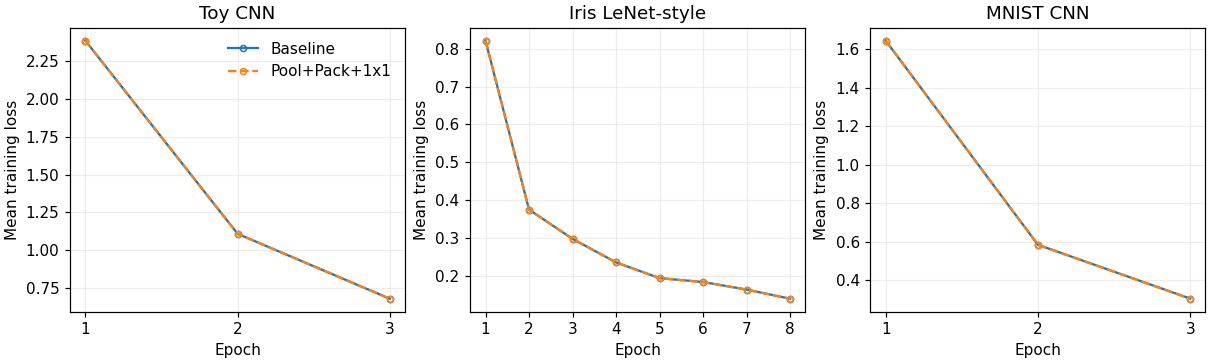

In [7]:
def fit(data, seed, variant):
    model = make_model(data, seed)
    optimizer = Adam(lr=0.003).setup(model)
    rand = np.random.default_rng(seed)
    x, y = data.train
    losses = []
    with enabled(variant):
        for _ in range(data.epochs):
            order = rand.permutation(len(y))
            total = 0.0
            for begin in range(0, len(y), data.training_batch):
                ids = order[begin:begin + data.training_batch]
                total += float(step(model, optimizer, (x[ids], y[ids]))) * len(ids)
            losses.append(total / len(y))
    return model, losses


def predict(data, model, variant):
    x, _ = data.test
    with enabled(variant), no_grad(), test_mode():
        return np.concatenate([model(x[i:i + 64]).data for i in range(0, len(x), 64)])


def metrics(data, logits):
    target = data.test[1]
    predicted = logits.argmax(axis=1)
    p, r, f1, _ = precision_recall_fscore_support(target, predicted, average='macro', zero_division=0)
    return np.array([(target == predicted).mean(), p, r, f1])


checkpoints, scores, curves, deltas = {}, {}, {}, {}
torch.set_num_threads(1)
with threadpool_limits(limits=1, user_api='blas'):
    for data in workloads:
        for seed in SEEDS:
            for variant in (BASE, ALL):
                model, losses = fit(data, seed, variant)
                curves[data.name, seed, variant] = losses
                scores[data.name, seed, variant] = metrics(data, predict(data, model, variant))
                if seed == SEEDS[0] and variant == BASE:
                    checkpoints[data.name] = model
            expected = predict(data, model, BASE)
            for variant in VARIANTS[1:]:
                actual = predict(data, model, variant)
                np.testing.assert_allclose(actual, expected, atol=4e-5, rtol=2e-4)
                np.testing.assert_array_equal(actual.argmax(axis=1), expected.argmax(axis=1))
                deltas[data.name, seed, variant] = np.max(np.abs(actual - expected))
            torch_model = TorchCNN(data, model)
            x = torch.from_numpy(data.test[0])
            with torch.inference_mode():
                actual = np.concatenate([torch_model(piece).numpy() for piece in x.split(64)])
            np.testing.assert_allclose(actual, expected, atol=4e-5, rtol=2e-4)
            np.testing.assert_array_equal(actual.argmax(axis=1), expected.argmax(axis=1))

fig, axes = plt.subplots(1, len(workloads), figsize=(11, 3.3), layout='constrained')
for data, ax in zip(workloads, axes):
    print(f'{data.name}: accuracy, macro precision, macro recall, macro F1')
    for variant in (BASE, ALL):
        stats = np.mean([scores[data.name, s, variant] for s in SEEDS], axis=0)
        print(f'  {label(variant):<17}', ' / '.join(f'{value:.4f}' for value in stats))
        losses = np.mean([curves[data.name, s, variant] for s in SEEDS], axis=0)
        epochs = np.arange(1, len(losses) + 1)
        ax.plot(epochs, losses, marker='o', markersize=4, markerfacecolor='none',
                linestyle='--' if variant == ALL else '-', label=label(variant))
    worst = max(deltas[data.name, seed, v] for seed in SEEDS for v in VARIANTS[1:])
    print(f'  {len(SEEDS) * len(data.test[1])} shared-weight predictions agreed, '
          f'maximum MyDeZero logit difference {worst:.2g}.', flush=True)
    ax.set(title=data.name, xlabel='Epoch', ylabel='Mean training loss', xticks=epochs)
    ax.grid(alpha=0.22)
axes[0].legend(frameon=False)
plt.show()

In [8]:
def copy_model(data, checkpoint, weight_dtype=np.float32):
    model = make_model(data, SEEDS[0], weight_dtype)
    for source, dest in zip(checkpoint.layers, model.layers):
        dest.W.data[...] = source.W.data
        dest.b.data[...] = source.b.data
    return model


def benchmark_models(data, checkpoint, batch):
    x = data.train[0][:batch]
    y = data.train[1][:batch].astype(np.int64, copy=False)
    xt, yt = torch.from_numpy(x), torch.from_numpy(y)
    torch_model = TorchCNN(data, checkpoint)
    infer = [(lambda v=v: enabled(v), lambda: checkpoint(x)) for v in VARIANTS]
    infer.append((nullcontext, lambda: torch_model(xt)))
    legacy_model = copy_model(data, checkpoint, legacy_dtype)
    with enabled(BASE), no_grad():
        np.testing.assert_allclose(legacy_model(x).data, checkpoint(x).data, atol=4e-5, rtol=2e-4)
    infer.append((lambda: enabled(BASE), lambda: legacy_model(x)))
    with no_grad(), test_mode(), torch.inference_mode():
        inference = sample_calls(infer)

    torch_training = TorchCNN(data, checkpoint).train()
    torch_optimizer = torch.optim.Adam(torch_training.parameters(), lr=0.003)
    training = []
    for variant in VARIANTS:
        model = copy_model(data, checkpoint)
        opt = Adam(lr=0.003).setup(model)
        training.append((lambda v=variant: enabled(v), lambda model=model, opt=opt: step(model, opt, (x, y))))
    training.append((nullcontext, lambda: torch_step(torch_training, torch_optimizer, (xt, yt))))
    legacy_optimizer = Adam(lr=0.003).setup(legacy_model)
    training.append((lambda: enabled(BASE), lambda: step(legacy_model, legacy_optimizer, (x, y))))
    return inference, sample_calls(training)


timing = {}
for threads in THREADS:
    torch.set_num_threads(threads)
    with threadpool_limits(limits=threads, user_api='blas'):
        for data in workloads:
            for batch in BATCHES:
                timing[threads, data.name, batch] = benchmark_models(data, checkpoints[data.name], batch)
            print(f'{data.name}, {threads} thread(s): all batches timed.', flush=True)

Toy CNN, 1 thread(s): all batches timed.
Iris LeNet-style, 1 thread(s): all batches timed.
MNIST CNN, 1 thread(s): all batches timed.
Toy CNN, 4 thread(s): all batches timed.
Iris LeNet-style, 4 thread(s): all batches timed.
MNIST CNN, 4 thread(s): all batches timed.


Toy CNN          1T b1  Inference P50|P95 ms 0.409|0.722 / 0.192|0.319 / 0.284|0.478 · samples/s 2442 / 5216 / 3516
Toy CNN          1T b1  Training  P50|P95 ms 1.199|1.500 / 1.023|1.311 / 1.337|1.882 · samples/s 834 / 977 / 748
Toy CNN          1T b16 Inference P50|P95 ms 0.510|0.820 / 0.228|0.437 / 0.590|0.756 · samples/s 31354 / 70114 / 27119
Toy CNN          1T b16 Training  P50|P95 ms 1.884|2.304 / 1.428|1.971 / 2.678|3.130 · samples/s 8493 / 11205 / 5974
Toy CNN          1T b64 Inference P50|P95 ms 0.725|0.919 / 0.300|0.530 / 0.773|1.132 · samples/s 88276 / 213689 / 82805
Toy CNN          1T b64 Training  P50|P95 ms 2.332|2.727 / 1.974|2.274 / 3.124|3.604 · samples/s 27445 / 32417 / 20487
Iris LeNet-style 1T b1  Inference P50|P95 ms 0.666|0.841 / 0.295|0.505 / 0.553|0.831 · samples/s 1501 / 3391 / 1808
Iris LeNet-style 1T b1  Training  P50|P95 ms 4.146|4.900 / 3.829|4.615 / 4.835|5.705 · samples/s 241 / 261 / 207
Iris LeNet-style 1T b16 Inference P50|P95 ms 3.982|5.033 / 1.936|2.

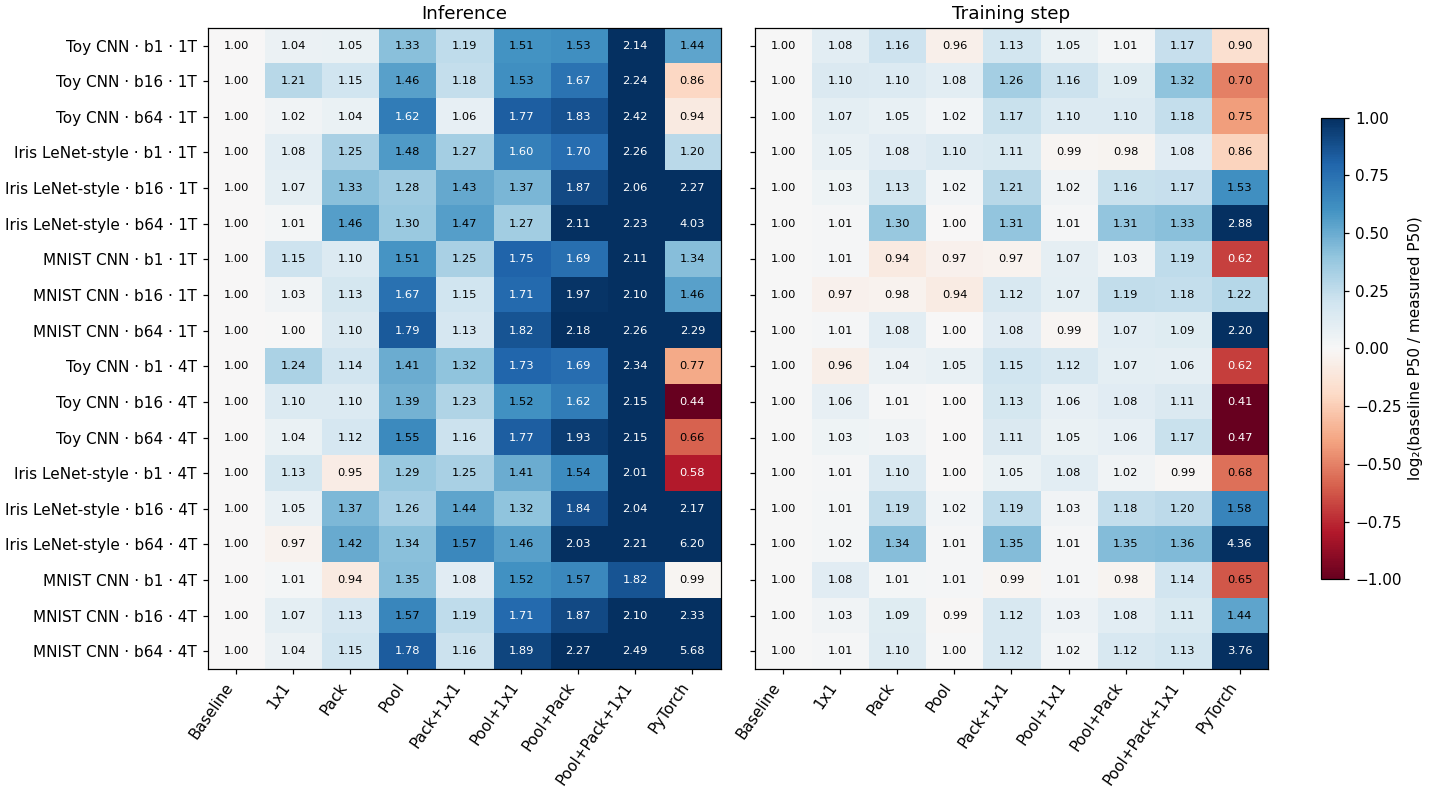

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 7.2), layout='constrained', sharey=True)
for index, (title, ax) in enumerate(zip(('Inference', 'Training step'), axes)):
    matrix = np.array([[rows[index][0][0] / measurement[0] for measurement in rows[index][:-1]]
                       for rows in timing.values()])
    # Use a logarithmic color scale while keeping the annotations in speedup units.
    image = ax.imshow(np.log2(matrix), aspect='auto', cmap='RdBu', vmin=-1.0, vmax=1.0)
    for row, col in np.ndindex(matrix.shape):
        ratio = matrix[row, col]
        ax.text(col, row, f'{ratio:.2f}', ha='center', va='center', fontsize=7.5,
                color='white' if abs(np.log2(ratio)) > 0.67 else 'black')
    ax.set(title=title)
    ax.set_xticks(np.arange(len(VARIANTS) + 1), [label(v) for v in VARIANTS] + ['PyTorch'],
                  rotation=55, ha='right')
axes[0].set_yticks(np.arange(len(timing)), [f'{name} · b{b} · {t}T' for t, name, b in timing])
fig.colorbar(image, ax=axes, label='log₂(baseline P50 / measured P50)', shrink=0.72)
plt.show()

for key, row in timing.items():
    threads, name, batch = key
    for phase, values in zip(('Inference', 'Training'), row):
        selected = (values[0], *values[-3:-1])
        latency = ' / '.join(f'{p50:.3f}|{p95:.3f}' for p50, p95 in selected)
        throughput = ' / '.join(f'{1000 * batch / p50:.0f}' for p50, _ in selected)
        print(f'{name:<16} {threads}T b{batch:<2} {phase:<9} '
              f'P50|P95 ms {latency} · samples/s {throughput}')

Toy CNN          1T b1  Inference     0.524|0.732 / 0.409|0.722 / 0.192|0.319
Toy CNN          1T b16 Inference     0.696|0.955 / 0.510|0.820 / 0.228|0.437
Toy CNN          1T b64 Inference     0.943|1.171 / 0.725|0.919 / 0.300|0.530
Iris LeNet-style 1T b1  Inference     0.818|0.951 / 0.666|0.841 / 0.295|0.505
Iris LeNet-style 1T b16 Inference     7.676|8.404 / 3.982|5.033 / 1.936|2.196
Iris LeNet-style 1T b64 Inference     32.980|35.002 / 18.682|20.397 / 8.384|9.797
MNIST CNN        1T b1  Inference     0.406|0.506 / 0.326|0.487 / 0.154|0.176
MNIST CNN        1T b16 Inference     9.801|10.783 / 4.863|5.511 / 2.320|2.715
MNIST CNN        1T b64 Inference     47.372|49.373 / 24.050|27.140 / 10.660|12.380
Toy CNN          4T b1  Inference     0.542|0.661 / 0.441|0.712 / 0.188|0.320
Toy CNN          4T b16 Inference     0.677|0.948 / 0.487|0.671 / 0.226|0.439
Toy CNN          4T b64 Inference     0.881|1.078 / 0.737|0.997 / 0.342|0.563
Iris LeNet-style 4T b1  Inference     0.751|1.081 / 0

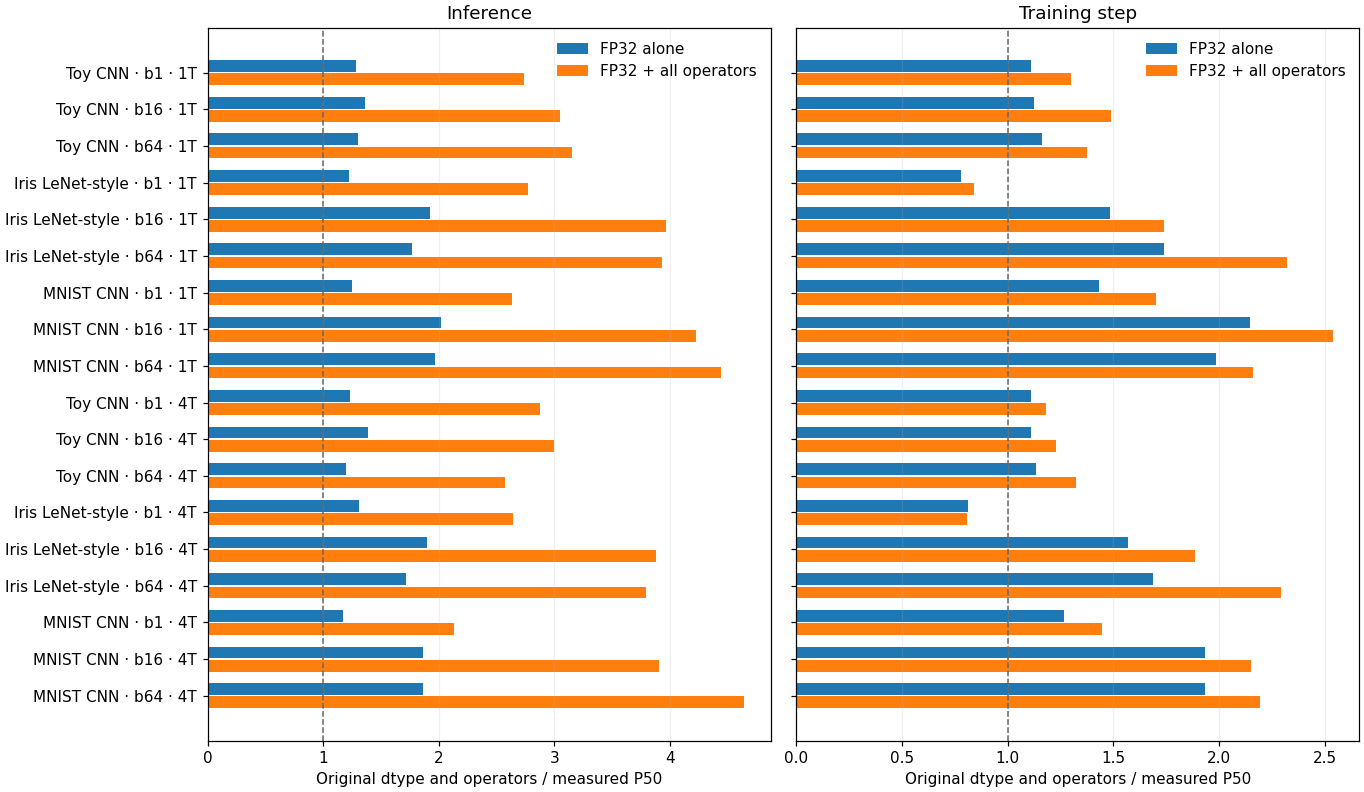

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12.4, 7.2), layout='constrained', sharey=True)
positions = np.arange(len(timing))
for index, (phase, ax) in enumerate(zip(('Inference', 'Training step'), axes)):
    dtype_speed, combined_speed = [], []
    for key, rows in timing.items():
        reference, optimized, _, legacy = (rows[index][0], *rows[index][-3:])
        dtype_speed.append(legacy[0] / reference[0])
        combined_speed.append(legacy[0] / optimized[0])
        threads, name, batch = key
        values = ' / '.join(f'{p50:.3f}|{p95:.3f}' for p50, p95 in (legacy, reference, optimized))
        print(f'{name:<16} {threads}T b{batch:<2} {phase:<13} {values}')
    ax.barh(positions - 0.18, dtype_speed, height=0.32, label='FP32 alone')
    ax.barh(positions + 0.18, combined_speed, height=0.32, label='FP32 + all operators')
    ax.axvline(1, color='0.4', linestyle='--', linewidth=1)
    ax.set(title=phase, xlabel='Original dtype and operators / measured P50')
    ax.grid(axis='x', alpha=0.2)
    ax.legend(frameon=False)
axes[0].set_yticks(positions, [f'{name} · b{b} · {t}T' for t, name, b in timing])
axes[0].invert_yaxis()
plt.show()
print(f'P50|P95 in ms: original operators with {legacy_dtype}, '
      'original operators with FP32, and optimized operators with FP32.')

## Results from the saved run

On NumPy 2.0.2, the old initializer produced FP64 weights. Against that
baseline, all four changes improved inference P50 by **2.14–4.64×** over
18 model, batch, and thread combinations. Training step P50 ranged from
**0.81–2.54×**. Iris at batch 1 was slower at both thread counts.

With FP32 fixed, the three operator changes improved inference P50 by
**1.82–2.49×** and gave **0.99–1.36×** training-step P50. All variants and
PyTorch agreed on 2,166 held-out predictions from shared FP32 weights. The
paired FP32 training runs had matching Toy and Iris mean classification scores.
MNIST mean accuracy was 92.33% for the original operators and 92.47% for the
optimized paths.

## What still limits CPU performance

The FP32 table lists the original operators, all optimized MyDeZero operators,
and PyTorch eager. The final figure compares each FP32 configuration against
the old operators with the dtype detected on this NumPy version. Each ratio
comes from matched measurements in this run. Ratios below 1 mark slowdowns.

The pooling optimization pays off in inference. Training still records
argmax indices and uses the existing input-gradient convolution. For larger
spatial filters, matrix multiplication or the cost of packing can dominate.
The VGG and ResNet operator cases measure representative shapes. The model
benchmarks use small networks and dataset subsets. PyTorch and MyDeZero keep
their own training implementations, including the optimizer and autograd.
